# What drives the price of a car?

![](images/kurt.jpeg)

**UC Berkeley ML/AI — Practical Application II**

**OVERVIEW**

In this application, you will explore a dataset from Kaggle. The original dataset contained information on 3 million used cars. The provided dataset contains information on 426K cars to ensure speed of processing. Your goal is to understand what factors make a car more or less expensive. As a result of your analysis, you should provide clear recommendations to your client -- a used car dealership -- as to what consumers value in a used car.

### CRISP-DM Framework

<center>
    <img src = images/crisp.png width = 50%/>
</center>

I follow the **CRISP-DM** process (Cross-Industry Standard Process for Data Mining): Business Understanding → Data Understanding → Data Preparation → Modeling → Evaluation → Deployment.

## 1. Business Understanding

> *Prompt: From a business perspective, we are tasked with identifying key drivers for used car prices. Reframe the task as a data task with the appropriate technical vocabulary.*


**Business question.** What makes a used car more or less expensive, and what should a dealership do with that knowledge?

**As a data problem.** This is a **supervised regression** task. The target is `price` (continuous, in dollars). The features are the vehicle's attributes (age, mileage, make, type, fuel, condition and so on) plus where it is listed. I will fit several regression models and use them in two ways:

1. **Predict** price well enough to be trusted. I measure this on data the model has never seen (R², MAE, RMSE, cross-validation).
2. **Explain** price. I rank features by how much the model relies on them (permutation importance) and check the *direction* of each effect separately (coefficients and grouped median prices), because importance alone says that a feature matters, not whether it raises or lowers price.

**Success criteria.** The final model should beat a naive baseline (always predict the median price) by a wide margin, show a small gap between training and test performance, and give conclusions a dealer can act on.

In [1]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, KFold, GridSearchCV, cross_val_score
from sklearn.compose import ColumnTransformer, TransformedTargetRegressor
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler, TargetEncoder
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.inspection import permutation_importance
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error

sns.set_theme(style="whitegrid")
RANDOM_STATE = 42

## 2. Data Understanding

> *Prompt: Get familiar with the data, identify any quality issues within, and explore what information it contains and how it could inform the business understanding.*


Before changing anything, I get to know the raw data: its size, types, how much is missing, and whether the values are believable.

**Step 1.** Read in `vehicles.csv`.

In [2]:
raw = pd.read_csv("data/vehicles.csv")
raw.head()

,id,region,price,year,manufacturer,model,condition,cylinders,fuel,odometer,title_status,transmission,VIN,drive,size,type,paint_color,state
0,7222695916,prescott,6000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,az
1,7218891961,fayetteville,11900,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,ar
2,7221797935,florida keys,21000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,fl
3,7222270760,worcester / central MA,1500,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,ma
4,7210384030,greensboro,4900,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,nc


**Step 2.** Size, data types and summary statistics.

In [3]:
print("Rows, columns:", raw.shape)
raw.info()

Rows, columns: (426880, 18)
<class 'pandas.DataFrame'>
RangeIndex: 426880 entries, 0 to 426879
Data columns (total 18 columns):
 #   Column        Non-Null Count   Dtype  
---  ------        --------------   -----  
 0   id            426880 non-null  int64  
 1   region        426880 non-null  str    
 2   price         426880 non-null  int64  
 3   year          425675 non-null  float64
 4   manufacturer  409234 non-null  str    
 5   model         421603 non-null  str    
 6   condition     252776 non-null  str    
 7   cylinders     249202 non-null  str    
 8   fuel          423867 non-null  str    
 9   odometer      422480 non-null  float64
 10  title_status  418638 non-null  str    
 11  transmission  424324 non-null  str    
 12  VIN           265838 non-null  str    
 13  drive         296313 non-null  str    
 14  size          120519 non-null  str    
 15  type          334022 non-null  str    
 16  paint_color   296677 non-null  str    
 17  state         426880 non-null  

In [4]:
raw.describe().T

,count,mean,std,min,25%,50%,75%,max
id,426880.0,7.311487e+09,4.473170e+06,7.207408e+09,7.308143e+09,7.312621e+09,7.315254e+09,7.317101e+09
price,426880.0,7.519903e+04,1.218228e+07,0.000000e+00,5.900000e+03,1.395000e+04,2.648575e+04,3.736929e+09
year,425675.0,2.011235e+03,9.452120e+00,1.900000e+03,2.008000e+03,2.013000e+03,2.017000e+03,2.022000e+03
odometer,422480.0,9.804333e+04,2.138815e+05,0.000000e+00,3.770400e+04,8.554800e+04,1.335425e+05,1.000000e+07


**Step 3.** How much is missing? Missing data decides which columns are usable.

,% missing
size,71.8
cylinders,41.6
condition,40.8
VIN,37.7
drive,30.6
paint_color,30.5
type,21.8
manufacturer,4.1
title_status,1.9
model,1.2


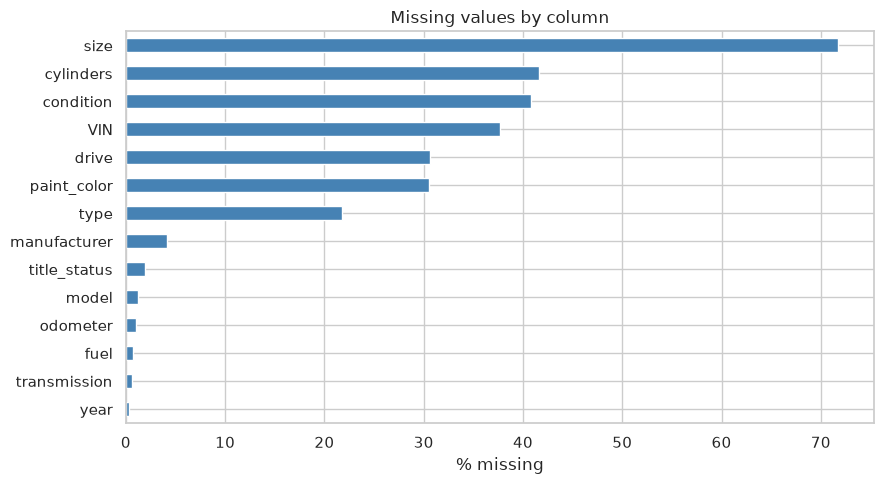

In [5]:
missing = (raw.isna().mean() * 100).sort_values(ascending=False)
display(missing.round(1).to_frame("% missing"))

fig, ax = plt.subplots(figsize=(9, 5))
missing[missing > 0].sort_values().plot.barh(ax=ax, color="steelblue")
ax.set_xlabel("% missing")
ax.set_title("Missing values by column")
plt.tight_layout(); plt.show()

**Step 4.** Are the values believable? Raw listings often contain junk (e.g. $0 prices, years from the 1900s, absurd mileage).

In [6]:
q = [0, .001, .01, .05, .5, .95, .99, .999, 1]
display(raw[["price", "year", "odometer"]].quantile(q).T)
print("Listings with price <= 0:", (raw.price <= 0).sum())
print("Listings with price > $150,000:", (raw.price > 150_000).sum())
print("Listings with odometer > 500,000:", (raw.odometer > 500_000).sum())

,0.000,0.001,0.010,0.050,0.500,0.950,0.990,0.999,1.000
price,0.0,0.0,0.0,0.0,13950.0,44500.0,66995.0,120000.0,3.736929e+09
year,1900.0,1932.0,1967.0,1998.0,2013.0,2020.0,2020.0,2021.0,2.022000e+03
odometer,0.0,0.0,2.0,6318.0,85548.0,204000.0,280000.0,1111111.0,1.000000e+07


Listings with price <= 0: 32895
Listings with price > $150,000: 196
Listings with odometer > 500,000: 1386


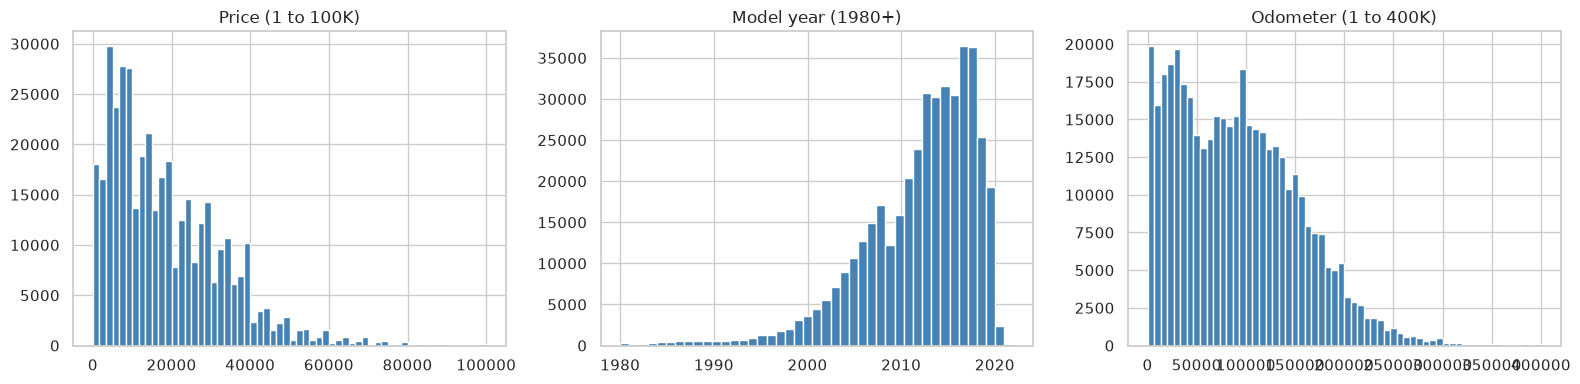

In [7]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
raw.loc[raw.price.between(1, 100_000), "price"].hist(bins=60, ax=axes[0], color="steelblue")
axes[0].set_title("Price (1 to 100K)")
raw.loc[raw.year >= 1980, "year"].hist(bins=43, ax=axes[1], color="steelblue")
axes[1].set_title("Model year (1980+)")
raw.loc[raw.odometer.between(1, 400_000), "odometer"].hist(bins=60, ax=axes[2], color="steelblue")
axes[2].set_title("Odometer (1 to 400K)")
plt.tight_layout(); plt.show()

**Step 5.** Categorical columns: how many distinct values, and which are most common?

In [8]:
cat_cols = raw.select_dtypes(include="object").columns
card = pd.DataFrame({
    "distinct": raw[cat_cols].nunique(),
    "top value": [raw[c].mode().iat[0] if raw[c].notna().any() else None for c in cat_cols],
    "top share %": [round(raw[c].value_counts(normalize=True).iat[0] * 100, 1) for c in cat_cols],
}).sort_values("distinct", ascending=False)
card

,distinct,top value,top share %
VIN,118246,1FMJU1JT1HEA52352,0.1
model,29649,f-150,1.9
region,404,columbus,0.8
state,51,ca,11.9
manufacturer,42,ford,17.3
type,13,sedan,26.1
paint_color,12,white,26.7
cylinders,8,6 cylinders,37.8
title_status,6,clean,96.8
condition,6,good,48.0


**What I found.**

- **Size:** 426,880 listings and 18 columns.
- **Lots of missing data:** `size` (72%), `cylinders` (42%), `condition` (41%), `VIN` (38%), `drive` (31%), `paint_color` (31%) and `type` (22%) are missing for many listings. Some listings contain only a region, a price and a state.
- **Clearly bad values:** 32,895 listings have a price of $0, and the highest price is $3.7 billion. Model years go back to 1900, and odometers go up to 10 million miles (1,386 listings are over 500,000 miles).
- **Very high-cardinality columns:** `model` has 29,649 distinct values, `region` has 404, and `VIN` is almost unique per row. `VIN` is useless as a feature, but `model` and `region` carry real signal if encoded carefully.
- **Skew:** the median price is $13,950, but the average is dragged up by absurd values, so I treat the raw mean as unreliable.

## 3. Data Preparation

> *Prompt: Handle integrity issues and cleaning, engineer new features, apply any transformations (scaling, logarithms, normalization), and prepare the data for modeling with `sklearn`.*


My principles:

- **Remove only what is clearly wrong using fixed domain rules** (impossible prices, years and mileage). I keep a log of how many rows each rule removes.
- **Don't throw away rows just because a field is missing.** Dropping every row with any missing value would discard most of this dataset. Missing values are filled **inside the modeling pipeline**, with statistics learned from the training data only.
- **Split into train and test before learning anything from the data** (imputation values, scaling, encodings), so the test score is honest.

**Step 1.** Fixed-rule filters, with a log of rows removed.

In [9]:
df = raw.copy()
log = [("raw data", len(df))]

def step(name, mask):
    global df
    df = df[mask].copy()
    log.append((name, len(df)))

step("price between $500 and $150,000", df.price.between(500, 150_000))
step("model year 1990 or later", df.year.ge(1990) | df.year.isna())
step("odometer under 500,000 miles (missing allowed)", df.odometer.lt(500_000) | df.odometer.isna())
step("odometer not zero", df.odometer.ne(0))
step("has a manufacturer or model (not an empty listing)", df.manufacturer.notna() | df.model.notna())

log = pd.DataFrame(log, columns=["step", "rows remaining"])
log["removed"] = (-log["rows remaining"].diff()).fillna(0).astype(int)
log

,step,rows remaining,removed
0,raw data,426880,0
1,"price between $500 and $150,000",384590,42290
2,model year 1990 or later,372758,11832
3,"odometer under 500,000 miles (missing allowed)",371892,866
4,odometer not zero,371012,880
5,has a manufacturer or model (not an empty list...,370950,62


**Step 2.** Drop columns that cannot help predict price: `id` (a unique key), `VIN` (a unique identifier, mostly missing), and `size` (about 72% missing). Then create features:

- `vehicle_age` = newest year in the data minus `year` (age is more directly meaningful than year).
- `cylinders` converted from text ("6 cylinders") to a number.
- `model` text is lower-cased and trimmed so that spelling variants merge.

In [10]:
df = df.drop(columns=["id", "VIN", "size"])

REF_YEAR = int(raw.year.max())
df["vehicle_age"] = REF_YEAR - df["year"]
df["cylinders"] = pd.to_numeric(df["cylinders"].str.extract(r"(\d+)")[0], errors="coerce")
df["model"] = df["model"].str.lower().str.strip()
df = df.drop(columns=["year"])

print("Reference year:", REF_YEAR)
print("Shape:", df.shape)
df.head()

Reference year: 2022
Shape: (370950, 15)


,region,price,manufacturer,model,condition,cylinders,fuel,odometer,title_status,transmission,drive,type,paint_color,state,vehicle_age
27,auburn,33590,gmc,sierra 1500 crew cab slt,good,8.0,gas,57923.0,clean,other,NaN,pickup,white,al,8.0
28,auburn,22590,chevrolet,silverado 1500,good,8.0,gas,71229.0,clean,other,NaN,pickup,blue,al,12.0
29,auburn,39590,chevrolet,silverado 1500 crew,good,8.0,gas,19160.0,clean,other,NaN,pickup,red,al,2.0
30,auburn,30990,toyota,tundra double cab sr,good,8.0,gas,41124.0,clean,other,NaN,pickup,red,al,5.0
31,auburn,15000,ford,f-150 xlt,excellent,6.0,gas,128000.0,clean,automatic,rwd,truck,black,al,9.0


**Step 3.** Define the target and features, then **split 80/20 before any learning from the data**.

In [11]:
y = df["price"]
X = df.drop(columns=["price"])

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=RANDOM_STATE)
print("Train:", X_train.shape, " Test:", X_test.shape)

Train: (296760, 14)  Test: (74190, 14)


**Step 4.** The preprocessing pipeline. Each column group gets a treatment suited to its type:

| Group | Columns | Treatment |
|---|---|---|
| Numeric | `vehicle_age`, `odometer`, `cylinders` | Median imputation (plus a "was missing" flag), then standard scaling |
| Low-cardinality categorical | `manufacturer`, `condition`, `fuel`, `title_status`, `transmission`, `drive`, `type`, `paint_color`, `state` | Fill missing with `"unknown"` (kept as its own category), then one-hot encode. Rare categories are grouped together |
| High-cardinality categorical | `model`, `region` | Fill missing with `"unknown"`, then **target encoding** (cross-fitted, so a row's own price is never used to encode it) |

Price is modeled on a **log scale** (`log1p`) because prices are right-skewed and errors are proportional. Predictions are converted back to dollars automatically.

In [12]:
num_cols = ["vehicle_age", "odometer", "cylinders"]
low_cat = ["manufacturer", "condition", "fuel", "title_status", "transmission",
           "drive", "type", "paint_color", "state"]
high_cat = ["model", "region"]

def make_preprocessor():
    return ColumnTransformer([
        ("num", Pipeline([("impute", SimpleImputer(strategy="median", add_indicator=True)),
                          ("scale", StandardScaler())]), num_cols),
        ("cat", Pipeline([("impute", SimpleImputer(strategy="constant", fill_value="unknown")),
                          ("onehot", OneHotEncoder(handle_unknown="infrequent_if_exist",
                                                   min_frequency=100, sparse_output=False))]), low_cat),
        ("high", Pipeline([("impute", SimpleImputer(strategy="constant", fill_value="unknown")),
                           ("target", TargetEncoder(target_type="continuous", random_state=RANDOM_STATE))]), high_cat),
    ])

def make_model(estimator):
    """Preprocessing + estimator, trained on log(price), predicting dollars."""
    return TransformedTargetRegressor(
        regressor=Pipeline([("prep", make_preprocessor()), ("model", estimator)]),
        func=np.log1p, inverse_func=np.expm1,
    )

## 4. Modeling

> *Prompt: Build a number of different regression models with price as the target. Explore different parameters and cross-validate your findings.*


I train a naive baseline and four real models and compare them on the same split. Hyperparameters are tuned with cross-validation on the **training set only**. The test set is used once, at the end, for scoring.

- **Baseline:** always predict the median training price.
- **Linear Regression:** simple, fully interpretable.
- **Ridge:** linear with a penalty that shrinks coefficients (handles correlated features). `alpha` tuned by grid search.
- **Lasso:** linear with a penalty that can shrink coefficients to exactly zero (automatic feature selection). `alpha` tuned by grid search.
- **Gradient Boosting:** a non-linear tree ensemble that can capture interactions (e.g. mileage matters differently for a 3-year-old car than a 15-year-old one).

In [13]:
cv = KFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
results = []
fitted = {}

def evaluate(name, model):
    """Fit on train, score on train/test, and cross-validate on train."""
    model.fit(X_train, y_train)
    est = model.best_estimator_ if hasattr(model, "best_estimator_") else model
    pred_tr, pred_te = est.predict(X_train), est.predict(X_test)
    cv_r2 = cross_val_score(est, X_train, y_train, cv=cv, scoring="r2", n_jobs=-1)
    results.append({
        "Model": name,
        "CV R² (train)": cv_r2.mean(),
        "Train R²": r2_score(y_train, pred_tr),
        "Test R²": r2_score(y_test, pred_te),
        "Test MAE ($)": mean_absolute_error(y_test, pred_te),
        "Test RMSE ($)": np.sqrt(mean_squared_error(y_test, pred_te)),
        "Best params": getattr(model, "best_params_", ""),
    })
    fitted[name] = est
    return est

In [14]:
evaluate("Baseline (median)", make_model(DummyRegressor(strategy="median")))
evaluate("Linear Regression", make_model(LinearRegression()))

,"regressor regressor: object, default=NoneRegressor object such as derived from:class:`~sklearn.base.RegressorMixin`. This regressor willautomatically be cloned each time prior to fitting. If `regressor isNone`, :class:`~sklearn.linear_model.LinearRegression` is created and used.",Pipeline(step...egression())])
,"func func: function, default=NoneFunction to apply to `y` before passing to :meth:`fit`. Cannot be setat the same time as `transformer`. If `func is None`, the function used will bethe identity function. If `func` is set, `inverse_func` also needs to beprovided. The function needs to return a 2-dimensional array.",<ufunc 'log1p'>
,"inverse_func inverse_func: function, default=NoneFunction to apply to the prediction of the regressor. Cannot be set atthe same time as `transformer`. The inverse function is used to returnpredictions to the same space of the original training labels. If`inverse_func` is set, `func` also needs to be provided. The inversefunction needs to return a 2-dimensional array.",<ufunc 'expm1'>
,"transformer transformer: object, default=NoneEstimator object such as derived from:class:`~sklearn.base.TransformerMixin`. Cannot be set at the same timeas `func` and `inverse_func`. If `transformer is None` as well as`func` and `inverse_func`, the transformer will be an identitytransformer. Note that the transformer will be cloned during fitting.Also, the transformer is restricting `y` to be a numpy array.",None
,"check_inverse check_inverse: bool, default=TrueWhether to check that `transform` followed by `inverse_transform`or `func` followed by `inverse_func` leads to the original targets.",True
Name,Type,Value
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Defined only when `X`has feature names that are all strings... versionadded:: 1.0","ndarray[object](14,)","['region','manufacturer','model',...,'paint_color','state','vehicle_age']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying regressor exposes such an attribute when fit... versionadded:: 0.24,int,14
regressor_ regressor_: objectFitted regressor.,Pipeline,Pipeline(step...egression())])
transformer_ transformer_: objectTransformer used in :meth:`fit` and :meth:`predict`.,FunctionTransformer,FunctionTrans...validate=True)
,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('prep', ...), ('model', ...)]"


In [15]:
ridge = GridSearchCV(make_model(Ridge()), {"regressor__model__alpha": [0.1, 1, 10, 100]},
                     cv=3, scoring="r2", n_jobs=-1)
evaluate("Ridge", ridge)

,"regressor regressor: object, default=NoneRegressor object such as derived from:class:`~sklearn.base.RegressorMixin`. This regressor willautomatically be cloned each time prior to fitting. If `regressor isNone`, :class:`~sklearn.linear_model.LinearRegression` is created and used.",Pipeline(step...(alpha=0.1))])
,"func func: function, default=NoneFunction to apply to `y` before passing to :meth:`fit`. Cannot be setat the same time as `transformer`. If `func is None`, the function used will bethe identity function. If `func` is set, `inverse_func` also needs to beprovided. The function needs to return a 2-dimensional array.",<ufunc 'log1p'>
,"inverse_func inverse_func: function, default=NoneFunction to apply to the prediction of the regressor. Cannot be set atthe same time as `transformer`. The inverse function is used to returnpredictions to the same space of the original training labels. If`inverse_func` is set, `func` also needs to be provided. The inversefunction needs to return a 2-dimensional array.",<ufunc 'expm1'>
,"transformer transformer: object, default=NoneEstimator object such as derived from:class:`~sklearn.base.TransformerMixin`. Cannot be set at the same timeas `func` and `inverse_func`. If `transformer is None` as well as`func` and `inverse_func`, the transformer will be an identitytransformer. Note that the transformer will be cloned during fitting.Also, the transformer is restricting `y` to be a numpy array.",None
,"check_inverse check_inverse: bool, default=TrueWhether to check that `transform` followed by `inverse_transform`or `func` followed by `inverse_func` leads to the original targets.",True
Name,Type,Value
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Defined only when `X`has feature names that are all strings... versionadded:: 1.0","ndarray[object](14,)","['region','manufacturer','model',...,'paint_color','state','vehicle_age']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying regressor exposes such an attribute when fit... versionadded:: 0.24,int,14
regressor_ regressor_: objectFitted regressor.,Pipeline,Pipeline(step...(alpha=0.1))])
transformer_ transformer_: objectTransformer used in :meth:`fit` and :meth:`predict`.,FunctionTransformer,FunctionTrans...validate=True)
,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('prep', ...), ('model', ...)]"


In [16]:
lasso = GridSearchCV(make_model(Lasso(max_iter=5000)), {"regressor__model__alpha": [0.0001, 0.001, 0.01]},
                     cv=3, scoring="r2", n_jobs=-1)
evaluate("Lasso", lasso)

,"regressor regressor: object, default=NoneRegressor object such as derived from:class:`~sklearn.base.RegressorMixin`. This regressor willautomatically be cloned each time prior to fitting. If `regressor isNone`, :class:`~sklearn.linear_model.LinearRegression` is created and used.",Pipeline(step..._iter=5000))])
,"func func: function, default=NoneFunction to apply to `y` before passing to :meth:`fit`. Cannot be setat the same time as `transformer`. If `func is None`, the function used will bethe identity function. If `func` is set, `inverse_func` also needs to beprovided. The function needs to return a 2-dimensional array.",<ufunc 'log1p'>
,"inverse_func inverse_func: function, default=NoneFunction to apply to the prediction of the regressor. Cannot be set atthe same time as `transformer`. The inverse function is used to returnpredictions to the same space of the original training labels. If`inverse_func` is set, `func` also needs to be provided. The inversefunction needs to return a 2-dimensional array.",<ufunc 'expm1'>
,"transformer transformer: object, default=NoneEstimator object such as derived from:class:`~sklearn.base.TransformerMixin`. Cannot be set at the same timeas `func` and `inverse_func`. If `transformer is None` as well as`func` and `inverse_func`, the transformer will be an identitytransformer. Note that the transformer will be cloned during fitting.Also, the transformer is restricting `y` to be a numpy array.",None
,"check_inverse check_inverse: bool, default=TrueWhether to check that `transform` followed by `inverse_transform`or `func` followed by `inverse_func` leads to the original targets.",True
Name,Type,Value
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Defined only when `X`has feature names that are all strings... versionadded:: 1.0","ndarray[object](14,)","['region','manufacturer','model',...,'paint_color','state','vehicle_age']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying regressor exposes such an attribute when fit... versionadded:: 0.24,int,14
regressor_ regressor_: objectFitted regressor.,Pipeline,Pipeline(step..._iter=5000))])
transformer_ transformer_: objectTransformer used in :meth:`fit` and :meth:`predict`.,FunctionTransformer,FunctionTrans...validate=True)
,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('prep', ...), ('model', ...)]"


In [17]:
gbr = GridSearchCV(make_model(HistGradientBoostingRegressor(random_state=RANDOM_STATE, early_stopping=True)),
                   {"regressor__model__max_leaf_nodes": [31, 63],
                    "regressor__model__learning_rate": [0.1, 0.2]},
                   cv=3, scoring="r2", n_jobs=-1)
evaluate("Gradient Boosting", gbr)

,"regressor regressor: object, default=NoneRegressor object such as derived from:class:`~sklearn.base.RegressorMixin`. This regressor willautomatically be cloned each time prior to fitting. If `regressor isNone`, :class:`~sklearn.linear_model.LinearRegression` is created and used.",Pipeline(step...m_state=42))])
,"func func: function, default=NoneFunction to apply to `y` before passing to :meth:`fit`. Cannot be setat the same time as `transformer`. If `func is None`, the function used will bethe identity function. If `func` is set, `inverse_func` also needs to beprovided. The function needs to return a 2-dimensional array.",<ufunc 'log1p'>
,"inverse_func inverse_func: function, default=NoneFunction to apply to the prediction of the regressor. Cannot be set atthe same time as `transformer`. The inverse function is used to returnpredictions to the same space of the original training labels. If`inverse_func` is set, `func` also needs to be provided. The inversefunction needs to return a 2-dimensional array.",<ufunc 'expm1'>
,"transformer transformer: object, default=NoneEstimator object such as derived from:class:`~sklearn.base.TransformerMixin`. Cannot be set at the same timeas `func` and `inverse_func`. If `transformer is None` as well as`func` and `inverse_func`, the transformer will be an identitytransformer. Note that the transformer will be cloned during fitting.Also, the transformer is restricting `y` to be a numpy array.",None
,"check_inverse check_inverse: bool, default=TrueWhether to check that `transform` followed by `inverse_transform`or `func` followed by `inverse_func` leads to the original targets.",True
Name,Type,Value
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Defined only when `X`has feature names that are all strings... versionadded:: 1.0","ndarray[object](14,)","['region','manufacturer','model',...,'paint_color','state','vehicle_age']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying regressor exposes such an attribute when fit... versionadded:: 0.24,int,14
regressor_ regressor_: objectFitted regressor.,Pipeline,Pipeline(step...m_state=42))])
transformer_ transformer_: objectTransformer used in :meth:`fit` and :meth:`predict`.,FunctionTransformer,FunctionTrans...validate=True)
,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('prep', ...), ('model', ...)]"


## 5. Evaluation

> *Prompt: Reflect on what makes a high-quality model and what we can learn from it. Review the business objective and decide whether earlier phases need revisiting or whether there is information of value to bring to the client.*


**Step 1.** Compare all models on the held-out test set. A model is good if its test R² is high, its MAE is low, and the gap between train and test R² is small (a big gap means overfitting).

In [18]:
comparison = pd.DataFrame(results).set_index("Model")
comparison["Overfit gap (R²)"] = comparison["Train R²"] - comparison["Test R²"]
display(comparison.drop(columns="Best params").round(3))
print()
print(comparison["Best params"].to_string())

,CV R² (train),Train R²,Test R²,Test MAE ($),Test RMSE ($),Overfit gap (R²)
Model,,,,,,
Baseline (median),-0.053,-0.053,-0.053,11210.896,15084.899,0.000
Linear Regression,0.710,0.734,0.710,4559.340,7909.354,0.023
Ridge,0.710,0.734,0.710,4559.328,7909.212,0.023
Lasso,0.709,0.734,0.712,4553.949,7890.078,0.022
Gradient Boosting,0.836,0.865,0.833,3254.853,6007.130,0.032



Model
Baseline (median)                                                     
Linear Regression                                                     
Ridge                                 {'regressor__model__alpha': 0.1}
Lasso                              {'regressor__model__alpha': 0.0001}
Gradient Boosting    {'regressor__model__learning_rate': 0.2, 'regr...


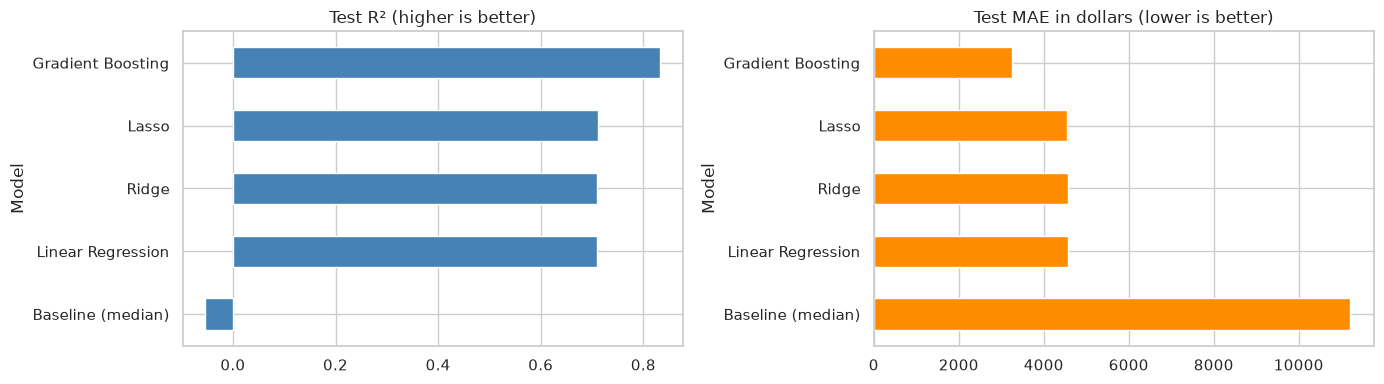

In [19]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
comparison["Test R²"].plot.barh(ax=axes[0], color="steelblue"); axes[0].set_title("Test R² (higher is better)")
comparison["Test MAE ($)"].plot.barh(ax=axes[1], color="darkorange"); axes[1].set_title("Test MAE in dollars (lower is better)")
plt.tight_layout(); plt.show()

Best model: Gradient Boosting


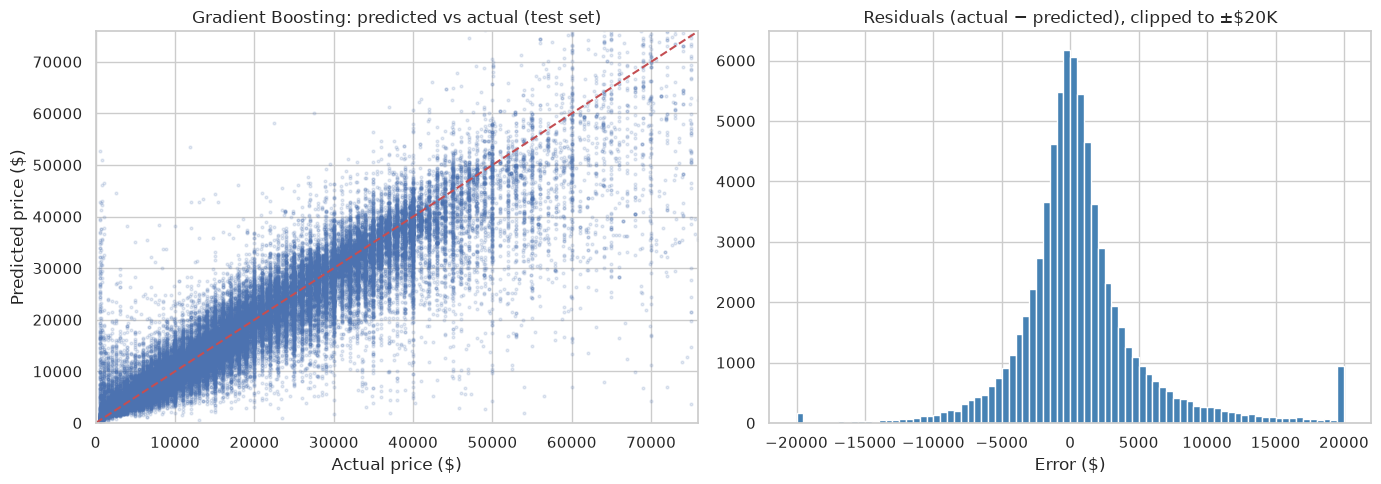

In [20]:
best_name = comparison.drop(index="Baseline (median)")["Test MAE ($)"].idxmin()
best = fitted[best_name]
pred = best.predict(X_test)
print("Best model:", best_name)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
axes[0].scatter(y_test, pred, s=4, alpha=0.15)
lim = [0, y_test.quantile(0.995)]
axes[0].plot(lim, lim, "r--"); axes[0].set_xlim(lim); axes[0].set_ylim(lim)
axes[0].set_xlabel("Actual price ($)"); axes[0].set_ylabel("Predicted price ($)")
axes[0].set_title(f"{best_name}: predicted vs actual (test set)")

resid = y_test - pred
axes[1].hist(resid.clip(-20000, 20000), bins=80, color="steelblue")
axes[1].set_title("Residuals (actual − predicted), clipped to ±$20K")
axes[1].set_xlabel("Error ($)")
plt.tight_layout(); plt.show()

**Step 2. Which features matter most?** *Permutation importance* shuffles one feature at a time on the **test set** and measures how much the prediction error (MAE) gets worse. A bigger increase means the model relies on that feature more. Shuffling is done on raw columns, so each original feature gets one score.

,feature,MAE increase ($),std
0,model,3456.9,39.2
1,vehicle_age,3321.1,36.9
2,odometer,1939.2,15.8
3,cylinders,646.3,9.6
4,manufacturer,637.5,12.9
5,condition,494.9,12.8
6,fuel,489.3,13.3
7,drive,465.1,6.1
8,type,416.3,5.0
9,state,194.4,10.9


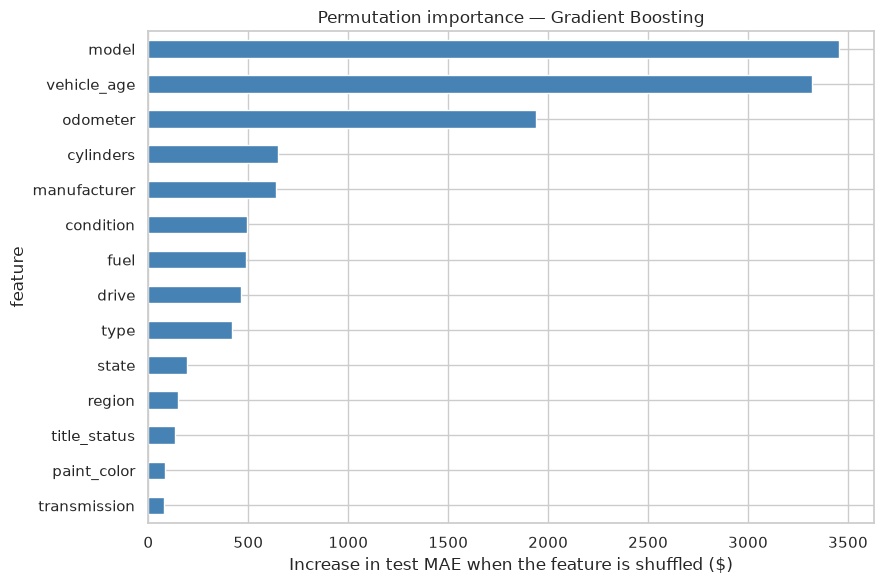

In [21]:
sample = X_test.sample(min(15_000, len(X_test)), random_state=RANDOM_STATE)
perm = permutation_importance(best, sample, y_test.loc[sample.index], n_repeats=5,
                              scoring="neg_mean_absolute_error", n_jobs=-1, random_state=RANDOM_STATE)
imp = pd.DataFrame({"feature": X_test.columns, "MAE increase ($)": perm.importances_mean,
                    "std": perm.importances_std}).sort_values("MAE increase ($)", ascending=False)
display(imp.round(1).reset_index(drop=True))

fig, ax = plt.subplots(figsize=(9, 6))
imp.sort_values("MAE increase ($)").plot.barh(x="feature", y="MAE increase ($)", xerr=imp.sort_values("MAE increase ($)")["std"],
                                              ax=ax, legend=False, color="steelblue")
ax.set_xlabel("Increase in test MAE when the feature is shuffled ($)")
ax.set_title(f"Permutation importance — {best_name}")
plt.tight_layout(); plt.show()

**Step 3. In which direction does each factor push price?** Importance does not say whether a feature raises or lowers price, so I look at median prices by group in the cleaned data (a plain, model-free view) and at the Ridge coefficients (which hold other features constant).

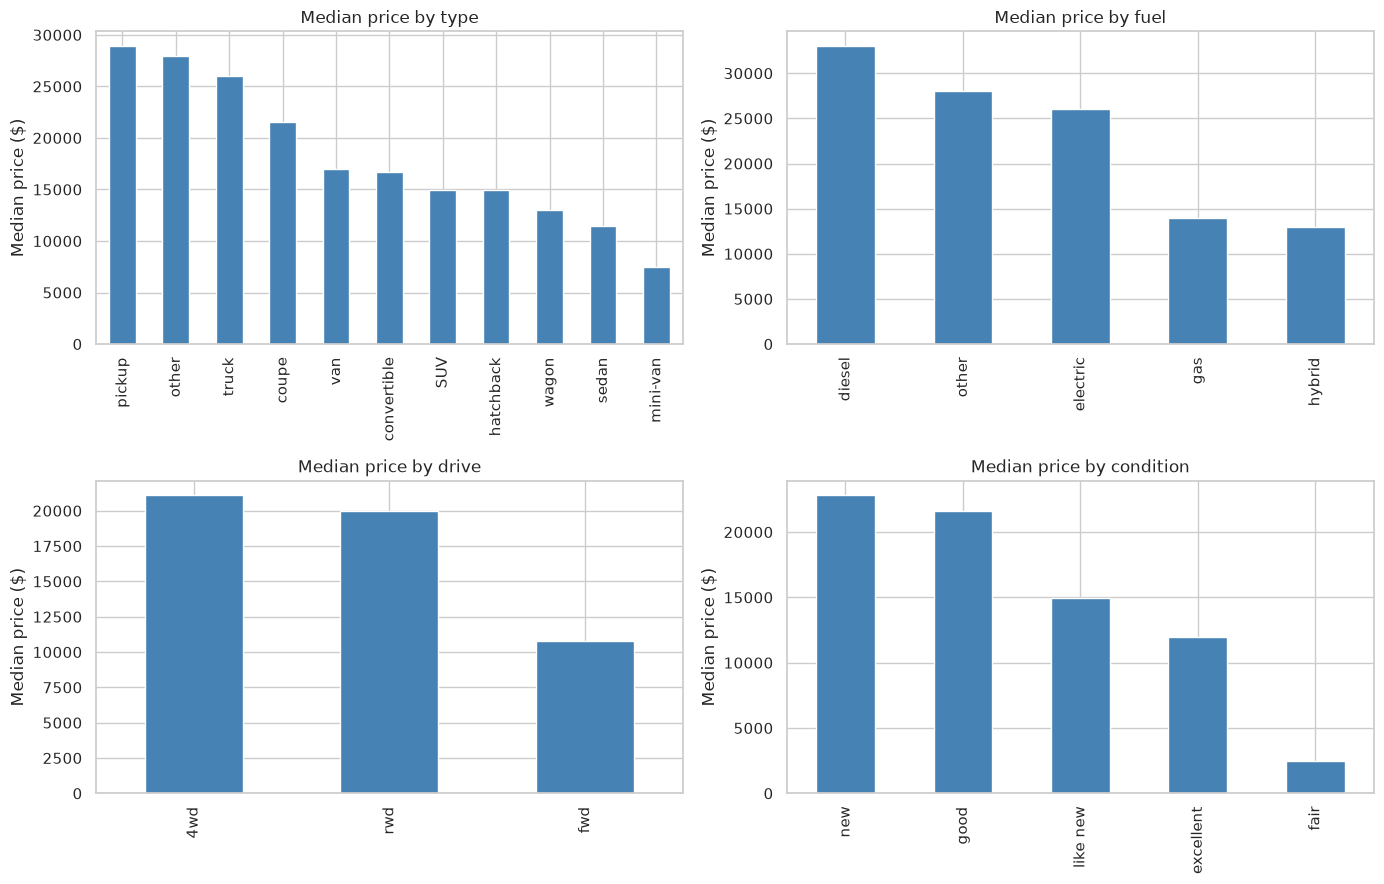

In [22]:
analysis = df.copy()

def median_by(col, order=None, min_n=500):
    g = analysis.groupby(col)["price"].agg(["median", "count"])
    g = g[g["count"] >= min_n].sort_values("median", ascending=False)
    return g

fig, axes = plt.subplots(2, 2, figsize=(14, 9))
for ax, col in zip(axes.ravel(), ["type", "fuel", "drive", "condition"]):
    g = median_by(col)
    g["median"].plot.bar(ax=ax, color="steelblue"); ax.set_title(f"Median price by {col}")
    ax.set_ylabel("Median price ($)"); ax.set_xlabel("")
plt.tight_layout(); plt.show()

In [23]:
for col in ["type", "fuel", "drive", "condition", "transmission"]:
    display(median_by(col)["median"].round(0).to_frame(f"median price by {col}").T)

type,pickup,other,truck,coupe,van,convertible,SUV,hatchback,wagon,sedan,mini-van
median price by type,28900.0,27990.0,26000.0,21590.0,16990.0,16700.0,14998.0,14990.0,12999.0,11500.0,7500.0


fuel,diesel,other,electric,gas,hybrid
median price by fuel,32995.0,27990.0,25990.0,13995.0,12995.0


drive,4wd,rwd,fwd
median price by drive,21080.0,19999.0,10795.0


condition,new,good,like new,excellent,fair
median price by condition,22800.0,21590.0,14950.0,11995.0,2500.0


transmission,other,automatic,manual
median price by transmission,28590.0,13495.0,10000.0


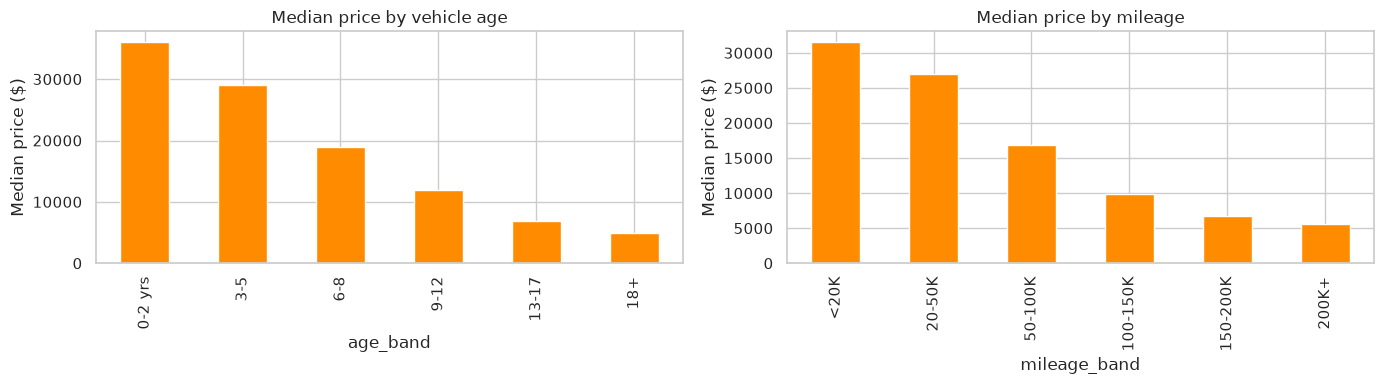

In [24]:
analysis["age_band"] = pd.cut(analysis.vehicle_age, [-1, 2, 5, 8, 12, 17, 40],
                              labels=["0-2 yrs", "3-5", "6-8", "9-12", "13-17", "18+"])
analysis["mileage_band"] = pd.cut(analysis.odometer, [0, 20_000, 50_000, 100_000, 150_000, 200_000, 500_000],
                                  labels=["<20K", "20-50K", "50-100K", "100-150K", "150-200K", "200K+"])
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
analysis.groupby("age_band", observed=True)["price"].median().plot(kind="bar", ax=axes[0], color="darkorange")
axes[0].set_title("Median price by vehicle age"); axes[0].set_ylabel("Median price ($)")
analysis.groupby("mileage_band", observed=True)["price"].median().plot(kind="bar", ax=axes[1], color="darkorange")
axes[1].set_title("Median price by mileage"); axes[1].set_ylabel("Median price ($)")
plt.tight_layout(); plt.show()

In [25]:
# Ridge coefficients are on log(price): exp(coef) - 1 is the approximate % change in price.
ridge_pipe = fitted["Ridge"].regressor_
names = ridge_pipe.named_steps["prep"].get_feature_names_out()
coefs = pd.Series(ridge_pipe.named_steps["model"].coef_, index=names)

cat_effects = coefs[coefs.index.str.startswith("cat__")]
cat_effects = (np.exp(cat_effects) - 1) * 100
cat_effects = cat_effects.rename(lambda s: s.replace("cat__", "")).sort_values()
cat_effects = cat_effects[~cat_effects.index.str.contains("infrequent")]  # rare categories lumped together are not interpretable
print("Largest price DISCOUNTS (approx % vs the average listing, other factors held constant):")
display(cat_effects.head(10).round(1).to_frame("% effect"))
print("Largest price PREMIUMS:")
display(cat_effects.tail(10).round(1).to_frame("% effect"))

num_effects = coefs[coefs.index.str.startswith("num__") & ~coefs.index.str.contains("missingindicator")]
print("Numeric features: % price change per +1 standard deviation (Ridge):")
display(((np.exp(num_effects) - 1) * 100).rename(lambda s: s.replace("num__", "")).round(1).to_frame("% per +1 SD"))

Largest price DISCOUNTS (approx % vs the average listing, other factors held constant):


,% effect
condition_salvage,-44.1
condition_fair,-38.2
title_status_missing,-33.3
manufacturer_fiat,-31.7
fuel_electric,-20.3
manufacturer_kia,-17.6
manufacturer_mitsubishi,-17.4
manufacturer_harley-davidson,-17.1
manufacturer_hyundai,-13.8
manufacturer_nissan,-12.2


Largest price PREMIUMS:


,% effect
condition_like new,24.3
title_status_unknown,24.8
condition_new,28.1
condition_unknown,28.3
condition_excellent,28.6
manufacturer_tesla,32.6
manufacturer_porsche,38.4
title_status_clean,41.0
fuel_diesel,47.0
title_status_lien,50.4


Numeric features: % price change per +1 standard deviation (Ridge):


,% per +1 SD
vehicle_age,-26.2
odometer,-17.5
cylinders,7.7


**Interpretation.**

**Data cleaning.** The fixed rules kept 370,950 of 426,880 rows (87%). The biggest cuts were prices outside $500–$150,000 (42,290 rows, mostly the $0 listings) and model years before 1990 (11,832 rows). Listings with a missing field were kept and filled inside the pipeline, which is why far more data survives than if every incomplete row had been dropped.

**Which model is best.** Gradient Boosting, with a test R² of 0.833 and a typical error (MAE) of about $3,255, compared with $11,211 for the naive "always predict the median" baseline. Its cross-validated R² (0.836) matches its test R² (0.833), so the result is stable. Train R² is 0.865, a gap of about 0.03, which is mild overfitting.

**Why not the linear models.** Linear Regression, Ridge and Lasso all land at R² ≈ 0.71 and MAE ≈ $4,550. They are nearly identical because, with ~300K training rows and a handful of features, the penalty in Ridge and Lasso hardly matters. The ~12-point R² jump for Gradient Boosting says that price is not a straight-line function of the features. Depreciation is not constant from year to year, and make and model effects interact with age and mileage.

**What matters most** (permutation importance on the test set, measured as how much the average error grows when a feature is shuffled):

1. `model` (+$3,457) and `vehicle_age` (+$3,321) are the two strongest.
2. `odometer` (+$1,939) is next.
3. `cylinders`, `manufacturer`, `condition`, `fuel`, `drive` and `type` each add roughly $400–$650.
4. `state` (+$194) and `region` (+$148) matter a little.
5. `paint_color` (+$83) and `transmission` (+$78) barely matter.

**Which direction.** Age and mileage push price down steeply. Median price falls from $35,990 for cars 0–2 years old to $4,999 for cars 18+ years old, and from $31,495 under 20,000 miles to $5,588 over 200,000 miles. In the Ridge model, each additional standard deviation of age lowers price by about 26%, and of mileage by about 17.5%, holding everything else constant. Salvage (−44%) and fair (−38%) condition carry large discounts, while excellent, new and like-new condition carry premiums of 24–29%. Diesel carries a premium (+47%) and electric a discount (−20%) once the other factors are held constant. Pickups and trucks have the highest median prices ($28,900 and $26,000) compared with sedans ($11,500).

**Caveats.**

- Raw medians mix factors together. For example, "good" condition has a higher raw median ($21,590) than "like new" ($14,950) only because of the age and type mix of the cars in each group. For that reason I trust the model-based effects, which hold other factors constant, more than the raw medians.
- Effects of rare or ambiguous categories (such as `title_status` "lien" or "unknown") should not be over-read. Rare categories were grouped and are not shown.
- This is Craigslist **asking** prices, not final sale prices, so the model predicts what sellers ask. The results show association, not cause.
- Remaining error is partly irreducible: trim level, accident history, options and seller behavior are not in the data.

In [26]:
# Key numbers to quote in the client report
print("Best model:", best_name)
print(f"  Test R²:  {comparison.loc[best_name, 'Test R²']:.3f}")
print(f"  Test MAE: ${comparison.loc[best_name, 'Test MAE ($)']:,.0f}")
print(f"  Baseline MAE: ${comparison.loc['Baseline (median)', 'Test MAE ($)']:,.0f}")
print("\nTop 5 features by permutation importance:")
print(imp.head(5)[["feature", "MAE increase ($)"]].round(0).to_string(index=False))
print("\nMedian price by mileage band:")
print(analysis.groupby("mileage_band", observed=True)["price"].median().round(0).to_string())
print("\nMedian price by age band:")
print(analysis.groupby("age_band", observed=True)["price"].median().round(0).to_string())

Best model: Gradient Boosting
  Test R²:  0.833
  Test MAE: $3,255
  Baseline MAE: $11,211

Top 5 features by permutation importance:
     feature  MAE increase ($)
       model            3457.0
 vehicle_age            3321.0
    odometer            1939.0
   cylinders             646.0
manufacturer             638.0

Median price by mileage band:
mileage_band
<20K        31495.0
20-50K      27000.0
50-100K     16800.0
100-150K     9900.0
150-200K     6800.0
200K+        5588.0

Median price by age band:
age_band
0-2 yrs    35990.0
3-5        28990.0
6-8        19000.0
9-12       11987.0
13-17       6900.0
18+         4999.0


### Report to Client: What Drives Used-Car Prices?

Dear Dealership Team,

I analyzed about 427,000 used-car listings (about 371,000 after removing obviously bad entries such as $0 prices, ancient model years and impossible mileage) to answer one question: **what makes a used car worth more or less?** Here is what I found.

#### The biggest price drivers

1. **Which car it is (make and model).** The exact model is the single strongest signal. Brand matters too: Tesla and Porsche carry premiums, while Fiat, Kia, Mitsubishi and Hyundai sell at discounts.
2. **Age.** The median asking price falls from about **$36,000** for cars 0–2 years old to **$29,000** at 3–5 years, **$19,000** at 6–8, **$12,000** at 9–12, and about **$5,000** for cars over 18 years old. The biggest dollar drops come between ages 3 and 12.
3. **Mileage.** Median asking price falls from about **$31,500** under 20,000 miles to **$16,800** at 50,000–100,000 miles and about **$5,600** over 200,000 miles.

#### Other factors that matter

| Factor | What the data says |
|---|---|
| **Condition** | Salvage and "fair" cars sell at roughly 40% discounts. Excellent, new and like-new cars command 24–29% premiums. |
| **Vehicle type** | Pickups and trucks have the highest median prices (about $26,000–$29,000), versus about $11,500 for sedans. |
| **Fuel** | Diesel carries a clear premium (about 47% in my model, with other factors held constant). |
| **Drive** | 4-wheel-drive cars have a median of about $21,000 against about $11,000 for front-wheel-drive. Part of that is because 4WD is common on trucks and SUVs. |
| **Location** | State and region have a small effect compared with the car itself. |

#### What doesn't matter much

**Paint color** and **transmission type** have almost no effect on price once everything else is accounted for. Don't pay a premium for a color, and don't turn away a car for it.

#### Recommendations

- **Favor younger, lower-mileage cars from brands and models with strong resale value.** Age and mileage are the main reasons a car's price falls, so inventory that is newer and lower-mileage holds its value better.
- **Lean into pickups and trucks** (and diesel where the local market wants it), which carry the highest prices.
- **Consider reconditioning cars in "fair" condition.** Condition has a large effect on price (excellent cars sell at about 28% premiums and fair cars at about 38% discounts, holding other factors constant), so check whether the repair cost is smaller than the price gap.
- **Be careful with salvage and unclear-title cars.** They sell at steep discounts, so pay accordingly.
- **Don't spend effort on paint color.**

#### How much to trust this

The best model predicts asking price to within about **$3,300 on average** (typical error) and explains about **83% of the variation in prices** on cars it had never seen. It is a strong guide for ranking and screening inventory, but not a replacement for a proper appraisal. It is based on Craigslist asking prices, not final sale prices, and it cannot see trim level, accident history or options.

#### Next steps

To sharpen this, I recommend adding actual sale prices, vehicle trim and accident history, and building separate local price benchmarks for the markets you buy in.